# [NOTICE]

**This notebook is organized by AI assistant (GPT6.0-Astra) from source notebooks.**

**Source notebooks have been deleted.**

**This notebooks has not yet been checked by human expert.**

# Input encoding 展示

直接调用 `input_encoder_fn.py`，观察同一输入在不同编码下的时间结构。
输入为 `[0, 1]` 内的原始像素值，使用 CPU；从此 notebook 所在目录运行。
图中的时间步从 **0** 开始，输出仅在 notebook 内展示。

In [1]:
from pathlib import Path
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../../../..").resolve()))
from spikingjelly.activation_based.model import input_encoder_fn as encode

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
torch.manual_seed(42)

T = 64
values = torch.tensor([0., .05, .1, .2, .4, .6, .8, 1.])
x = values.reshape(1, 1, 1, -1)  # [B, C, H, W]
print("Input shape:", tuple(x.shape))
print("Pixel values:", ", ".join(f"{v:.2f}" for v in values))

Input shape: (1, 1, 1, 8)
Pixel values: 0.00, 0.05, 0.10, 0.20, 0.40, 0.60, 0.80, 1.00


## 1. Identity / Repeat：保留连续值

Identity 保持原输入；Repeat 添加时间轴，每一步都是相同的像素值。两者不会把输入变成二值脉冲。

Identity: (1, 1, 1, 8)
Repeat: (64, 1, 1, 1, 8) [T, B, C, H, W]


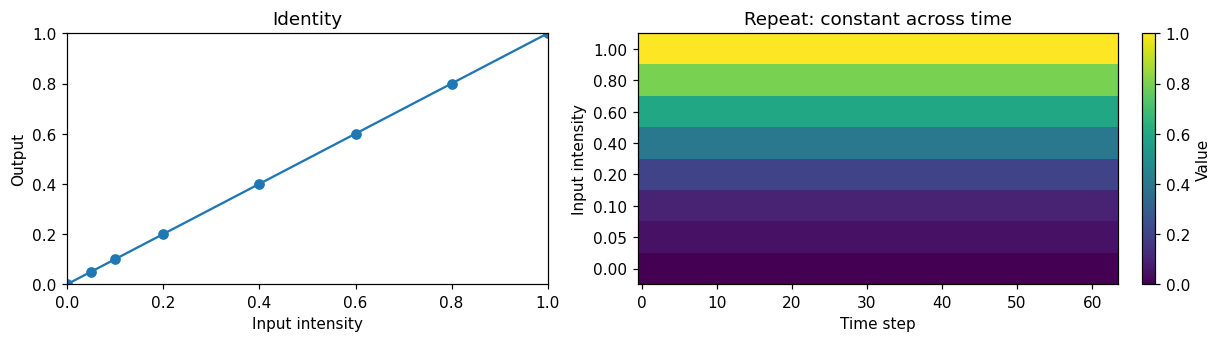

In [2]:
identity = encode.identity_encode_image(x)
repeated = encode.repeat_encode_image(x, T)
print("Identity:", tuple(identity.shape))
print("Repeat:", tuple(repeated.shape), "[T, B, C, H, W]")

fig, axes = plt.subplots(1, 2, figsize=(11, 3), constrained_layout=True)
axes[0].plot(values, identity.flatten(), "o-")
axes[0].set(xlabel="Input intensity", ylabel="Output", title="Identity", xlim=(0, 1), ylim=(0, 1))
heatmap = axes[1].imshow(repeated[:, 0, 0, 0].T, aspect="auto", origin="lower", vmin=0, vmax=1, cmap="viridis")
axes[1].set(yticks=np.arange(len(values)), yticklabels=[f"{v:.2f}" for v in values],
            xlabel="Time step", ylabel="Input intensity", title="Repeat: constant across time")
fig.colorbar(heatmap, ax=axes[1], label="Value")
plt.show()

## 2. 脉冲时序：相同强度，不同表达方式

- **Poisson**：这里的实现是每步按像素强度做 Bernoulli 采样，单次计数有波动。
- **Quantization**：将 `round(x × T)` 个脉冲分布到时间窗口中。
- **Latency**：强度越高，发放越早；展示 linear / log 两种映射。默认零输入也在最后一步发放。
- **Burst**：强度控制脉冲间隔；这里限制最多 3 个脉冲，零输入静默。
- **Phase**：振荡电流驱动 LIF。强度影响周期内的时序，也会改变脉冲数，并非每周期固定一个脉冲。

Spike counts over T=64; columns follow the input intensities above
Poisson                    [0, 2, 7, 13, 31, 46, 56, 64]
Quantization               [0, 3, 6, 13, 26, 38, 51, 64]
Latency: linear            [1, 1, 1, 1, 1, 1, 1, 1]
Latency: log               [1, 1, 1, 1, 1, 1, 1, 1]
Burst: max 3 spikes        [0, 3, 3, 3, 3, 3, 3, 3]
Phase: P=16, tau=2         [0, 4, 4, 12, 24, 36, 44, 60]


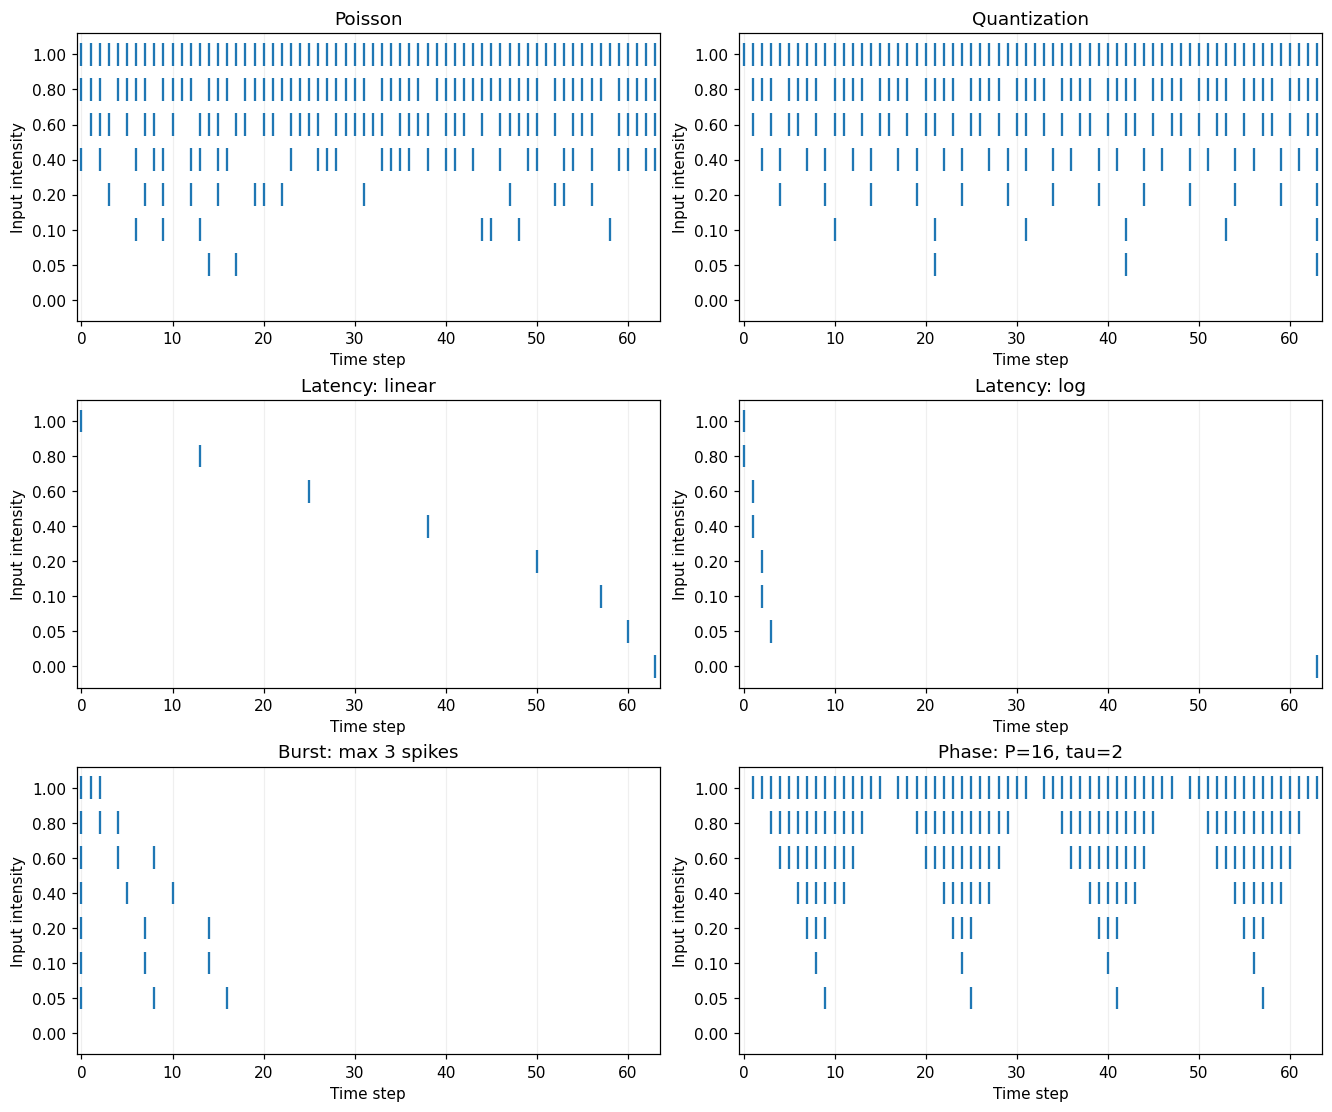

In [3]:
torch.manual_seed(42)
poisson = encode.poisson_encode_image(x, T)
quantized = encode.quantization_encode_image(x, T)
latency_linear = encode.latency_encode_image(x, T, mode="linear")
latency_log = encode.latency_encode_image(x, T, mode="log")
burst = encode.burst_encode_image(x, T, max_spikes=3, isi_min=1, isi_max=8)
phase = encode.phase_encode_image(x, T, P=16, tau=2.)

trains = [poisson, quantized, latency_linear, latency_log, burst, phase]
titles = ["Poisson", "Quantization", "Latency: linear", "Latency: log", "Burst: max 3 spikes", "Phase: P=16, tau=2"]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True, sharey=True, constrained_layout=True)
for ax, spikes, title in zip(axes.flat, trains, titles):
    times = [torch.nonzero(spikes[:, 0, 0, 0, j]).flatten().numpy() for j in range(len(values))]
    ax.eventplot(times, lineoffsets=np.arange(len(values)), linelengths=.65, colors="tab:blue")
    ax.set(title=title, xlim=(-.5, T-.5), ylim=(-.6, len(values)-.4),
           yticks=np.arange(len(values)), yticklabels=[f"{v:.2f}" for v in values],
           xlabel="Time step", ylabel="Input intensity")
    ax.tick_params(labelleft=True, labelbottom=True)
    ax.grid(axis="x", alpha=.2)
plt.show()

print("Spike counts over T=64; columns follow the input intensities above")
for title, spikes in zip(titles, trains):
    print(f"{title:26s}", spikes.sum(0).flatten().int().tolist())

## 3. Rate 与 Phase 的两个观察角度

左图比较随机采样的平均发放率与确定性的量化发放率；阴影为 128 次独立采样的 ±1 标准差。
右图只看 Phase 的最后一个周期，便于观察强度与周期内发放位置的关系。

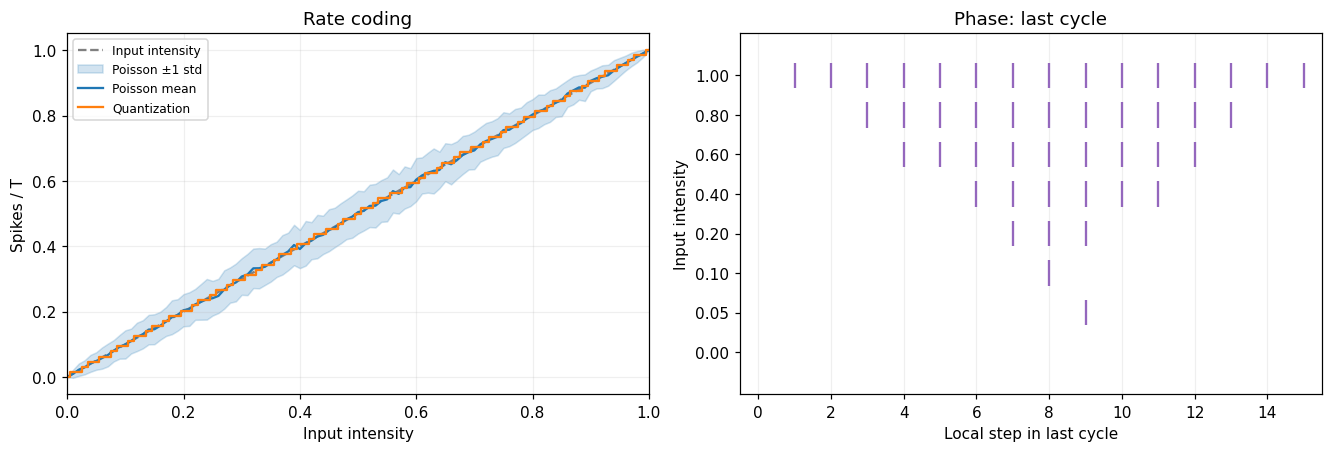

In [4]:
torch.manual_seed(42)
intensities = torch.linspace(0, 1, 101)
rate_input = intensities.reshape(1, 1, 1, -1)
poisson_trials = encode.poisson_encode_image(rate_input.repeat(128, 1, 1, 1), T)
trial_rates = poisson_trials.mean(0)[:, 0, 0]
mean_rate = trial_rates.mean(0)
std_rate = trial_rates.std(0)
quantized_rate = encode.quantization_encode_image(rate_input, T).mean(0).flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(intensities, intensities, "--", color="gray", label="Input intensity")
axes[0].fill_between(intensities, mean_rate-std_rate, mean_rate+std_rate, alpha=.2, color="tab:blue", label="Poisson ±1 std")
axes[0].plot(intensities, mean_rate, color="tab:blue", label="Poisson mean")
axes[0].step(intensities, quantized_rate, where="mid", color="tab:orange", label="Quantization")
axes[0].set(xlabel="Input intensity", ylabel="Spikes / T", title="Rate coding", xlim=(0, 1))
axes[0].legend(fontsize=8)
axes[0].grid(alpha=.2)

phase_times = [torch.nonzero(phase[-16:, 0, 0, 0, j]).flatten().numpy() for j in range(len(values))]
axes[1].eventplot(phase_times, lineoffsets=np.arange(len(values)), linelengths=.65, colors="tab:purple")
axes[1].set(xlabel="Local step in last cycle", ylabel="Input intensity", title="Phase: last cycle",
            xlim=(-.5, 15.5), xticks=np.arange(0, 16, 2),
            yticks=np.arange(len(values)), yticklabels=[f"{v:.2f}" for v in values])
axes[1].grid(axis="x", alpha=.2)
plt.show()

### Phase：独立递推对照

正式编码使用 LIFNode；下面用 NumPy 按同一方程独立递推，展示逐时间步的输出差异。
参数仍由正式函数计算，因此这里对照的是 **LIF 动力学实现**，不是独立验证参数校准方法。

\[
H_t=(1-1/\tau)V_{t-1}+ax+b-A\cos(2\pi t/P),\quad
S_t=\mathbf{1}[H_t\geq1],\quad V_t=H_t-S_t.
\]

每次输入从零状态开始，周期之间保留膜电位，采用减法重置。下方两个差异数值为 0 表示本组输入的脉冲逐项一致。

In [5]:
import math

phase_values = np.array([0., .05, .1, .1156, .1492, .2, .5, .75, .9312, 1.])
phase_T, phase_P, phase_tau = 64, 16, 2.
a, b, A = encode._phase_current_parameters(phase_P, phase_tau)
phase_input = torch.tensor(phase_values, dtype=torch.float64).reshape(1, 1, 1, -1)
phase_actual = encode.phase_encode_image(phase_input, phase_T, P=phase_P, tau=phase_tau)[:, 0, 0, 0].numpy()

voltage = np.zeros_like(phase_values)
reference = []
for t in range(phase_T):
    current = a * phase_values + b - A * math.cos(2 * math.pi * t / phase_P)
    charged = (1 - 1 / phase_tau) * voltage + current
    spike = charged >= 1.
    voltage = charged - spike
    reference.append(spike)
reference_spikes = np.array(reference, dtype=np.float64)
difference = np.abs(phase_actual - reference_spikes)

print(f"P={phase_P}, tau={phase_tau}; a={a:.6f}, b={b:.6f}, A={A:.6f}")
print("Different spike entries:", int(difference.sum()))
print("Maximum absolute difference:", float(difference.max()))
print("Input     LIF count    NumPy count")
for value, actual_count, reference_count in zip(phase_values, phase_actual.sum(0), reference_spikes.sum(0)):
    print(f"{value:7.4f}   {int(actual_count):9d}    {int(reference_count):11d}")

P=16, tau=2.0; a=2.665280, b=-0.689896, A=1.273313
Different spike entries: 0
Maximum absolute difference: 0.0
Input     LIF count    NumPy count
 0.0000           0              0
 0.0500           4              4
 0.1000           4              4
 0.1156           8              8
 0.1492          12             12
 0.2000          12             12
 0.5000          32             32
 0.7500          44             44
 0.9312          52             52
 1.0000          60             60


## 4. Population：一个像素由多个单元共同表达

这里使用 3 个 anchor：`0 / 0.5 / 1`。Gaussian 电流经 LIF 变成二值脉冲。
宽度由正式函数按 T 校准；最偏好的输入每步发放，距最远端一半的位置目标计数为 `round(T/e)`。
单个单元可以静默。

Population: (32, 1, 3, 1, 8) [T, B, C × population_size, H, W]


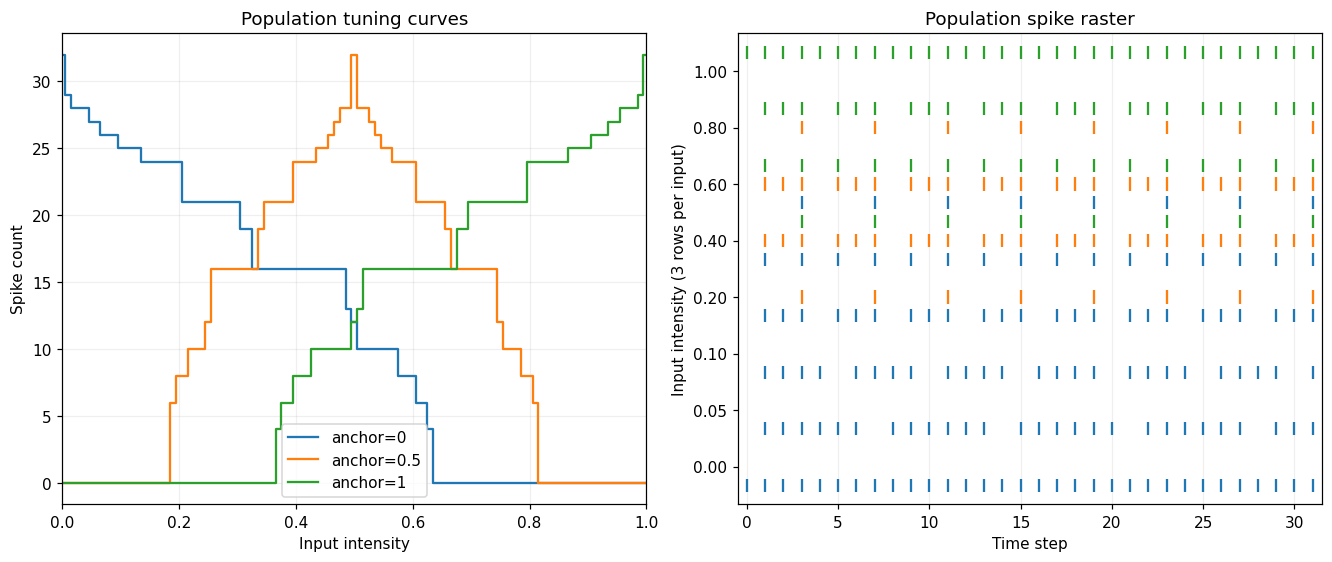

In [6]:
population_T = 32
population = encode.population_encode_image(x, population_T, population_size=3)
population_curve = encode.population_encode_image(rate_input, population_T, population_size=3)
counts = population_curve.sum(0)[0, :, 0]
anchors = [0., .5, 1.]
colors = ["tab:blue", "tab:orange", "tab:green"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for j, anchor, color in zip(range(3), anchors, colors):
    axes[0].step(intensities, counts[j], where="mid", color=color, label=f"anchor={anchor:g}")
    times = [torch.nonzero(population[:, 0, j, 0, k]).flatten().numpy() for k in range(len(values))]
    axes[1].eventplot(times, lineoffsets=np.arange(len(values))*3+j, linelengths=.7, colors=color)
axes[0].set(xlabel="Input intensity", ylabel="Spike count", title="Population tuning curves", xlim=(0, 1))
axes[0].legend()
axes[0].grid(alpha=.2)
axes[1].set(xlabel="Time step", ylabel="Input intensity (3 rows per input)", title="Population spike raster",
            xlim=(-.5, population_T-.5), ylim=(-1, len(values)*3),
            yticks=np.arange(len(values))*3+1, yticklabels=[f"{v:.2f}" for v in values])
axes[1].grid(axis="x", alpha=.2)
plt.show()
print("Population:", tuple(population.shape), "[T, B, C × population_size, H, W]")

## 5. 合成 RGB 图像：Population 的通道展开

R 从左到右增加，G 反向变化，B 保持 0.5。编码后 RGB 共 3 个通道展开为 9 个通道。
下图显示时间平均发放率，原始编码输出仍是二值脉冲。

Input: (1, 3, 16, 48) → encoded: (32, 1, 9, 16, 48)
Channel order: R0, R1, R2, G0, G1, G2, B0, B1, B2


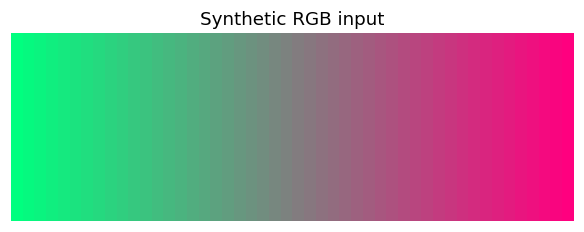

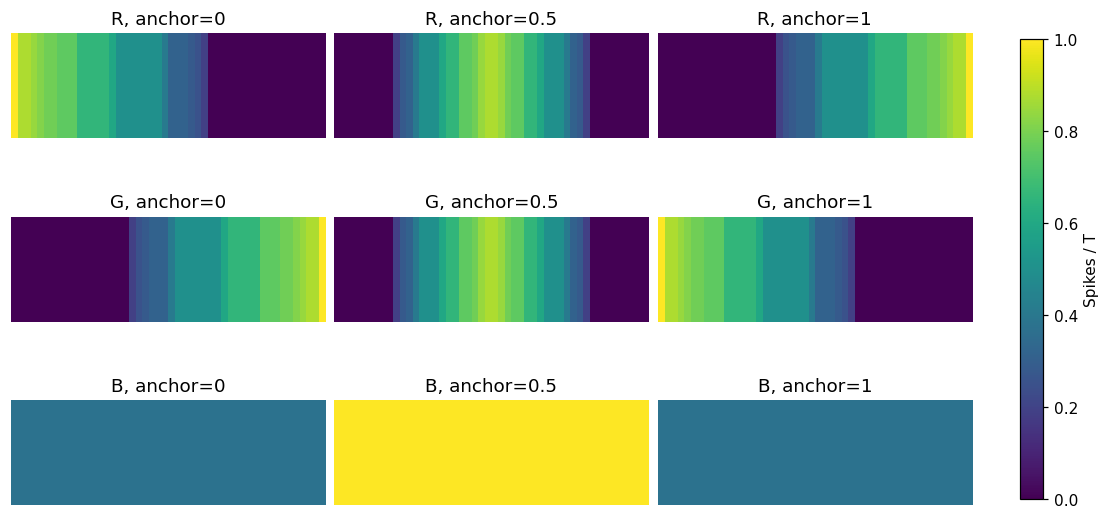

In [7]:
ramp = torch.linspace(0, 1, 48).repeat(16, 1)
image = torch.stack((ramp, 1-ramp, torch.full_like(ramp, .5))).unsqueeze(0)
image_spikes = encode.population_encode_image(image, population_T, population_size=3)
rates = image_spikes.mean(0)[0]
print("Input:", tuple(image.shape), "→ encoded:", tuple(image_spikes.shape))
print("Channel order: R0, R1, R2, G0, G1, G2, B0, B1, B2")

fig, ax = plt.subplots(figsize=(8, 2), constrained_layout=True)
ax.imshow(image[0].permute(1, 2, 0))
ax.set_title("Synthetic RGB input")
ax.axis("off")
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(10, 5), constrained_layout=True)
for c, name in enumerate("RGB"):
    for j, anchor in enumerate(anchors):
        heatmap = axes[c, j].imshow(rates[c*3+j], vmin=0, vmax=1, cmap="viridis")
        axes[c, j].set_title(f"{name}, anchor={anchor:g}")
        axes[c, j].axis("off")
fig.colorbar(heatmap, ax=axes.ravel().tolist(), label="Spikes / T", shrink=.85)
plt.show()

## Phase：设计依据与适用范围

`P` 与 `tau` 决定校准；正式函数通过线性规划求 `a / b / A`，约束零状态启动和周期稳态下的端点发放，并最大化共同阈值裕量。`T` 决定输出长度，需覆盖完整周期。阈值固定为 1，无输入衰减、无可训练编码参数；可行性检查留在 `.py` 中。

以下来源线索从旧 notebook 保留，用于追溯设计背景；本次整理没有重新核验文献，也不将当前组合实现视为其中某篇论文的直接复现：

- [McLelland & Paulsen (2009)](https://doi.org/10.1113/jphysiol.2008.164111)：持续与振荡驱动下的相位编码背景。
- [Brian2 phase-locking 示例](https://brian2.readthedocs.io/en/stable/examples/phase_locking.html)：相关演示，重置方式和参数映射与这里不同。
- [Amil et al. (2024)](https://doi.org/10.1371/journal.pcbi.1012628) / [作者代码](https://github.com/adriamilcar/Phase-Coding-in-LIF)：LIF 相位编码背景。
- [Rostro-Gonzalez et al. (2012)](https://doi.org/10.1088/1741-2560/9/2/026024) / [相关预印本](https://arxiv.org/abs/0905.4810)：脉冲模式参数估计与线性规划。
- [Resonate Spiking Neuron (2021)](https://doi.org/10.1609/aaai.v35i8.16870)：相关振荡神经元工作，不是此处模型。
- [Rhythm-SNN (2025)](https://www.nature.com/articles/s41467-025-63771-x) / [作者代码](https://github.com/YinsongYan/Rhythm-SNN)：节律门控背景，区别于这里的加性振荡电流。

当前实现是图像输入加端点校准的特定设计。它保留负电流和负膜电位，没有不应期；共享外加振荡与减法重置也不等于完整生理模型。这里的数值对照不证明创新性，亦不证明实际数据集上的训练收益。

本展示使用原始 `[0, 1]` 输入。正式函数根据输入是否越界来决定是否反归一化；已归一化但恰好仍落在 `[0, 1]` 的输入无法靠该规则识别。